<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Test Environment for Generative AI classroom labs

This lab provides a test environment for the codes generated using the Generative AI classroom.

Follow the instructions below to set up this environment for further use.


# Setup


### Install required libraries

In case of a requirement of installing certain python libraries for use in your task, you may do so as shown below.


In [1]:
%pip install seaborn
import piplite

await piplite.install(['nbformat', 'plotly'])

### Dataset URL from the GenAI lab
Use the URL provided in the GenAI lab in the cell below. 


In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0271EN-SkillsNetwork/labs/v1/m3/data/used_car_price_analysis.csv"

### Downloading the dataset

Execute the following code to download the dataset in to the interface.

> Please note that this step is essential in JupyterLite. If you are using a downloaded version of this notebook and running it on JupyterLabs, then you can skip this step and directly use the URL in pandas.read_csv() function to read the dataset as a dataframe


In [3]:
from pyodide.http import pyfetch

async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

path = URL

await download(path, "data1.csv")
file_name  = "data1.csv"

---


# Test Environment


In [4]:
#Reads a CSV from the provided file path into a pandas DataFrame, using the first row as column headers.
import pandas as pd

file_path = "data1.csv"
dataframe = pd.read_csv(file_path)

print(dataframe.head(5))

<ipython-input-4-d3ca7887661a>:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


     model  year transmission  mileage fuelType    tax   mpg  engineSize  \
0   Fiesta  2017    Automatic    15944   Petrol  150.0  57.7         1.0   
1    Focus  2018       Manual     9083   Petrol  150.0  57.7         1.0   
2    Focus  2017       Manual    12456   Petrol  150.0  57.7         1.0   
3   Fiesta  2019       Manual    10460   Petrol  145.0  40.3         1.5   
4   Fiesta  2019    Automatic     1482   Petrol  145.0  48.7         1.0   

   price  
0  12000  
1  14000  
2  13000  
3  17500  
4  16500  


In [7]:
# Identify the columns of a data frame with missing values.

missing_columns = dataframe.columns[dataframe.isna().any()]

print("Columns with missing values:")
print(missing_columns)

# Replace the missing values thus identified with mean value of the column.
dataframe[missing_columns] = dataframe[missing_columns].fillna(
    dataframe[missing_columns].mean(numeric_only=True)
)

# Deletes the duplicate entries from the data frame.
dataframe = dataframe.drop_duplicates()

Columns with missing values:
Index([], dtype='object')


In [9]:
# Identifies the top 5 attributes with highest correlation with the 'Price'

top_5_attributes = (
    dataframe.corr(numeric_only=True)["price"]
    .drop("price")
    .abs()
    .sort_values(ascending=False)
    .head(5)
)

print(top_5_attributes)

year          0.635715
mileage       0.530483
engineSize    0.411451
tax           0.405970
mpg           0.346263
Name: price, dtype: float64


In [10]:
# Count the number of cars under each unique value of fuelType attribute

fuel_type_counts = dataframe["fuelType"].value_counts()

print(fuel_type_counts)

fuelType
Petrol      12081
Diesel       5706
Hybrid         22
Electric        2
Other           1
Name: count, dtype: int64


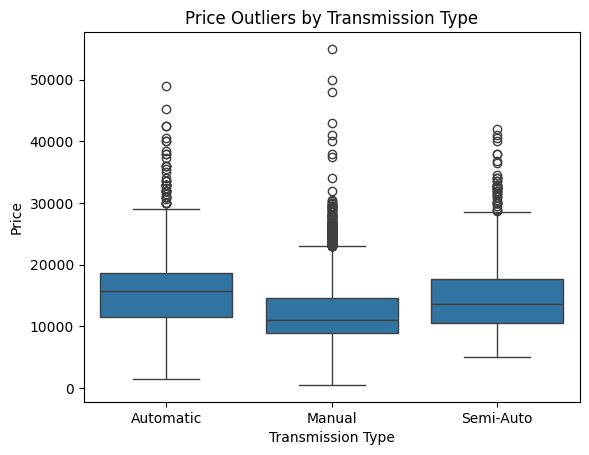

In [11]:
# Creates a Seaborn box plot between a 'transmission' and 'price'

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=dataframe, x="transmission", y="price")
plt.xlabel("Transmission Type")
plt.ylabel("Price")
plt.title("Price Outliers by Transmission Type")
plt.show()

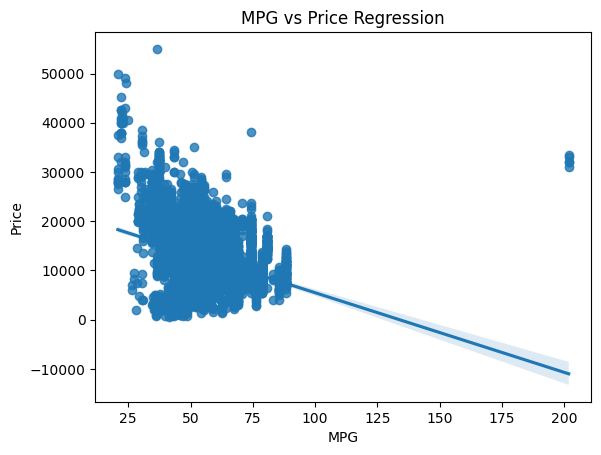

In [12]:
# Creates a regression plot between 'MPG' and 'price'

import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(data=dataframe, x="mpg", y="price")
plt.xlabel("MPG")
plt.ylabel("Price")
plt.title("MPG vs Price Regression")
plt.show()

In [13]:
# Fit a linear regression model on a 'price' on basis of 'mpg'
# Calculate the R^2 values and MSE values for this model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = dataframe[["mpg"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)

R²: 0.1504343741072478
MSE: 19049855.140110757


In [14]:
# Fit a linear regression model on a 'price' on basis of 'year, mileage, tax, mpg and engineSize'
# Calculate the R^2 values and MSE values for this model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = dataframe[["year", "mileage", "tax", "mpg", "engineSize"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R²:", r2_score(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))

R²: 0.6917125923771564
MSE: 6912744.910746688


In [15]:
# Create a pipeline with standard scalar, second degree polynomial features and linear regression model.
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = dataframe[["year", "mileage", "tax", "mpg", "engineSize"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2)),
    ("regression", LinearRegression())
])

# Fit this pipeline for a target variable using a set of source attributes from a dataframe.
pipeline.fit(X_train, y_train)
predictions = pipeline.predict(X_test)

# Evaluate the R^2 and MSE values for the trained model.
print("R²:", r2_score(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))

R²: 0.12122807147174242
MSE: 19704749.61491952


In [16]:
# Assuming that a subset of the attributes of a data frame are source attributes and one of the attributes is a target attribute, split the data into training and testing data assuming the testing data to be 20%.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

X = dataframe[["year", "mileage", "tax", "mpg", "engineSize"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and fit a Ridge regression model using the training data, setting the regularization parameter to 0.1.
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train, y_train)

predictions = ridge_model.predict(X_test)

# Calculate the MSE and R^2 values for the Ridge Regression model using the testing data.
print("R²:", r2_score(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))

R²: 0.6917134446113138
MSE: 6912725.801054926


In [17]:
# Assuming that a subset of the attributes of a data frame are source attributes and one of the attributes is a target attribute, split the data into training and testing data assuming the testing data to be 20%.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

X = dataframe[["year", "mileage", "tax", "mpg", "engineSize"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Apply second degree polynomial scaling to the training and testing data.
polynomial = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

# Create and fit a Ridge regression model using the training data, setting the regularization parameter to 0.1.
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train_poly, y_train)

predictions = ridge_model.predict(X_test_poly)

# Calculate the MSE and R^2 values for the Ridge Regression model using the testing data.
print("R²:", r2_score(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))

/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.1777e-24): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


R²: 0.673274888823681
MSE: 7326174.5165419085


In [18]:
# Assuming that a subset of the attributes of a data frame are source attributes and one of the attributes is a target attribute, split the data into training and testing data assuming the testing data to be 20%.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

X = dataframe[["year", "mileage", "tax", "mpg", "engineSize"]]
y = dataframe["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Apply second degree polynomial scaling to the training and testing data.
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Create and fit a Grid search on Ridge regression with cross validation using the training data, for a set of values of the parameter alpha.
parameters = {"alpha": [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    Ridge(),
    parameters,
    cv=4,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train_poly, y_train)

predictions = grid_search.predict(X_test_poly)

# Calculate the MSE and R^2 values for the Ridge Regression model using the testing data.
print("Best alpha:", grid_search.best_params_["alpha"])
print("R²:", r2_score(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))

/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=3.0567e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.98143e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=3.10209e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.85743e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.9414e-24): resul

Best alpha: 0.01
R²: 0.38273414165699104
MSE: 13840985.11755802


In [12]:
#Normalize the CPU_frequency column by its maximum value in place, replacing the original data without creating a new attribute.

df['CPU_frequency'] /= df['CPU_frequency'].max()


In [22]:
print(df.columns.tolist())

['Unnamed: 0', 'Manufacturer', 'Category', 'GPU', 'OS', 'CPU_core', 'CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'Price', 'Screen_Size_inch', 'Weight_pounds', 'Screen_Full HD', 'Screen_IPS Panel']


In [25]:
df[["Screen_Full HD", "Screen_IPS Panel"]] = (
    df[["Screen_Full HD", "Screen_IPS Panel"]].astype(int)
)

In [26]:
import pandas as pd

# Convert the categorical Screen column into indicator variables
df1 = pd.get_dummies(df["Screen"], prefix="Screen")

# Append the new indicator columns to the original DataFrame
df = df.join(df1)

# Remove the original categorical column
df.drop(columns=["Screen"], inplace=True)

# View the result
print(df.head())

<class 'KeyError'>: 'Screen'

## Authors


[Abhishek Gagneja](https://www.linkedin.com/in/abhishek-gagneja-23051987/)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-12-10|0.1|Abhishek Gagneja|Initial Draft created|


Copyright © 2023 IBM Corporation. All rights reserved.
